## Task 4: Sentiment Analysis with TF-IDF, Naive Bayes and Logistic Regression

In [1]:
pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import os, re
from functools import lru_cache
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, LeaveOneOut
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

SEED = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

for pkg in ["stopwords", "wordnet", "omw-1.4", "movie_reviews"]:
    nltk.download(pkg, quiet=True)

## 1. Text cleaning

In [3]:
STOP = set(stopwords.words("english")) - {"no", "nor", "not"}
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemma(word):
    # verb pass first ("loved" -> "love"), then noun pass ("reviews" -> "review")
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, "v"), "n")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)            # HTML tags
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)            # didn't -> did not
    text = re.sub(r"[^a-z\s]", " ", text)           # punctuation and digits
    tokens = [t for t in text.split() if len(t) > 1 and t not in STOP]
    return " ".join(lemma(t) for t in tokens)

example = "Not worth the money, plenty of better alternatives available."
default_stop = set(stopwords.words("english"))
naive = " ".join(t for t in re.sub(r"[^a-z\s]", " ", example.lower()).split() if t not in default_stop)
print("Original                :", example)
print("Default stopword removal:", naive)
print("With negations kept     :", clean_text(example))
print()
print("HTML + contraction test :", clean_text("<br />I didn't like it, and it can't be fixed!"))

Original                : Not worth the money, plenty of better alternatives available.
Default stopword removal: worth money plenty better alternatives available
With negations kept     : not worth money plenty better alternative available

HTML + contraction test : not like not fix


## 2. Pipeline and the predict_sentiment() function¶
   
TfidfVectorizer(max_features=5000) sits inside a scikit-learn Pipeline with the classifier, so the vocabulary and IDF weights are learned from training data only. Cleaning is row-by-row, so it can safely run before the split without leaking anything.

In [4]:
def make_pipeline(model, **tfidf_kwargs):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000, **tfidf_kwargs)),
                     ("model", model)])

def predict_sentiment(text, model, show=True):
    """Return (label, confidence) for a raw review string using a fitted pipeline."""
    cleaned = clean_text(text)
    vocab = model.named_steps["tfidf"].vocabulary_
    if not any(tok in vocab for tok in cleaned.split()):
        if show:
            print(f"UNKNOWN   (no known words)  <- {text}")
        return "unknown", 0.0
    proba = model.predict_proba([cleaned])[0]
    label = "positive" if proba[1] >= 0.5 else "negative"
    if show:
        print(f"{label.upper():9s} ({max(proba):.0%})  <- {text}")
    return label, float(max(proba))

Part A: the provided file (10 reviews)

In [5]:
sample = pd.read_csv("sentiment_reviews.csv")
print("Shape:", sample.shape)
print(sample["sentiment"].value_counts().to_string())
binary = sample[sample["sentiment"].isin(["positive", "negative"])].copy()
print("\nThe task is binary, so the one neutral review is dropped. Rows left:", len(binary))
binary["clean"] = binary["review_text"].map(clean_text)
binary[["review_text", "clean", "sentiment"]]

Shape: (10, 3)
sentiment
positive    5
negative    4
neutral     1

The task is binary, so the one neutral review is dropped. Rows left: 9


,review_text,clean,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceed expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrive complete...,negative
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stop work two day extremely disappoint purchase,negative
5,Customer support helped resolve my setup quest...,customer support help resolve setup question w...,positive
6,Delivery was slow and package was missing one ...,delivery slow package miss one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


In [6]:
y_small = (binary["sentiment"] == "positive").astype(int)
small_models = {"Multinomial Naive Bayes": MultinomialNB(),
                "Logistic Regression": LogisticRegression(max_iter=1000)}
rows, preds = [], {}
for name, model in small_models.items():
    p = cross_val_predict(make_pipeline(model), binary["clean"], y_small, cv=LeaveOneOut())
    preds[name] = p
    rows.append({"Model": name, "Leave-one-out accuracy": round(accuracy_score(y_small, p), 3),
                 "Correct": f"{int((p == y_small).sum())} of {len(y_small)}"})
print(f"Always guessing 'positive' scores {y_small.mean():.3f}.")
display(pd.DataFrame(rows))

detail = binary[["review_text", "sentiment"]].copy()
for name, p in preds.items():
    detail[name] = np.where(p == 1, "positive", "negative")
detail

Always guessing 'positive' scores 0.556.


,Model,Leave-one-out accuracy,Correct
0,Multinomial Naive Bayes,0.111,1 of 9
1,Logistic Regression,0.111,1 of 9


,review_text,sentiment,Multinomial Naive Bayes,Logistic Regression
0,"The product quality is exceptional, exceeded a...",positive,negative,negative
1,Terrible customer service and the item arrived...,negative,positive,positive
3,"Absolutely love this! Easy to setup, robust, a...",positive,negative,negative
4,Stopped working after two days. Extremely disa...,negative,positive,positive
5,Customer support helped resolve my setup quest...,positive,positive,positive
6,Delivery was slow and package was missing one ...,negative,positive,positive
7,Clean interface and intuitive controls. Highly...,positive,negative,negative
8,"Not worth the money, plenty of better alternat...",negative,positive,positive
9,Great value and durable build. Would definitel...,positive,negative,negative


In [7]:
small_nb = make_pipeline(MultinomialNB()).fit(binary["clean"], y_small)
for phrase in ["I love this, it works great", "Terrible, it broke after a day",
               "The weather is nice today", "Not worth the money"]:
    predict_sentiment(phrase, small_nb)

POSITIVE  (64%)  <- I love this, it works great
NEGATIVE  (57%)  <- Terrible, it broke after a day
UNKNOWN   (no known words)  <- The weather is nice today
NEGATIVE  (60%)  <- Not worth the money


Reading Part A. Leave-one-out accuracy is 1 of 9 for both models, worse than the 0.556 you get by always guessing "positive". That doesn't mean the models are anti-informative. These nine reviews share almost no useful words, so each prediction falls back on the class balance of the other eight, and holding a review out shifts that balance against its own class (hold out a positive and the rest lean negative, and the reverse). The one correct prediction is the review that shares the word "setup" with another positive review. The pipeline runs correctly here; the numbers measure the tiny sample, not the method. Part B fixes that.

## Part B: the same pipeline on 2,000 labelled movie reviews

In [8]:
reviews = pd.DataFrame({
    "text": [movie_reviews.raw(f) for f in movie_reviews.fileids()],
    "label": [movie_reviews.categories(f)[0] for f in movie_reviews.fileids()]})
reviews["y"] = (reviews["label"] == "pos").astype(int)
print("Shape:", reviews.shape)
print(reviews["label"].value_counts().to_string())
print("Duplicate review texts:", int(reviews["text"].duplicated().sum()))
reviews["clean"] = reviews["text"].map(clean_text)
print("Average words per review after cleaning:", int(reviews["clean"].str.split().str.len().mean()))

Shape: (2000, 3)
label
neg    1000
pos    1000
Duplicate review texts: 0
Average words per review after cleaning: 357


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews["clean"], reviews["y"], test_size=0.2, stratify=reviews["y"], random_state=SEED)
print("Train:", len(X_train), "| Test:", len(X_test), "| Positive share:", round(y_train.mean(), 3))

models = {"Multinomial Naive Bayes": lambda: MultinomialNB(),
          "Logistic Regression": lambda: LogisticRegression(max_iter=1000)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

fitted, rows = {}, []
for name, build in models.items():
    pipe = make_pipeline(build())
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "CV accuracy": f"{cv_scores.mean():.3f} +/- {cv_scores.std():.3f}",
                 "Test accuracy": round(accuracy_score(y_test, pred), 4),
                 "Precision": round(precision_score(y_test, pred), 4),
                 "Recall": round(recall_score(y_test, pred), 4),
                 "F1": round(f1_score(y_test, pred), 4),
                 "ROC-AUC": round(roc_auc_score(y_test, prob), 4)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/results.csv", index=False)
results

Train: 1600 | Test: 400 | Positive share: 0.5


,Model,CV accuracy,Test accuracy,Precision,Recall,F1,ROC-AUC
0,Multinomial Naive Bayes,0.824 +/- 0.013,0.8100,0.8333,0.775,0.8031,0.8917
1,Logistic Regression,0.843 +/- 0.014,0.8375,0.8140,0.875,0.8434,0.9150


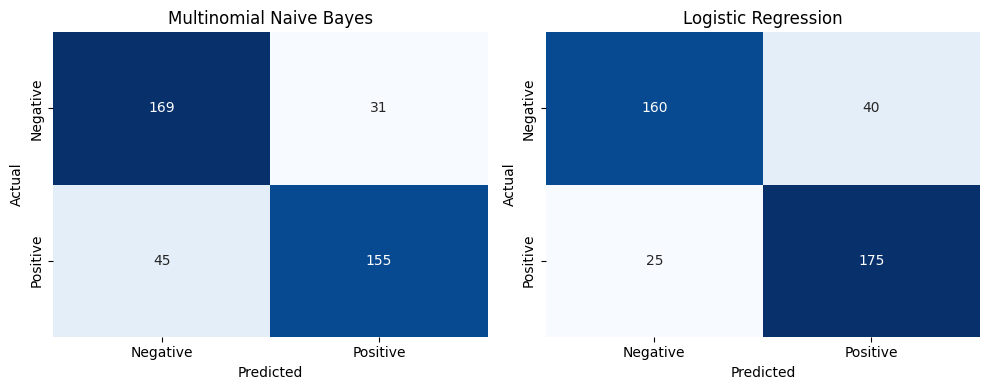

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.tight_layout()
fig.savefig(f"{OUT}/01_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### Does a bigger vocabulary window help? Unigrams vs unigrams+bigrams (5-fold CV on the training set)

In [11]:
rows = []
for ngram in [(1, 1), (1, 2)]:
    for name, build in models.items():
        s = cross_val_score(make_pipeline(build(), ngram_range=ngram), X_train, y_train,
                            cv=cv, scoring="accuracy")
        rows.append({"Model": name, "N-grams": "unigrams" if ngram == (1, 1) else "unigrams + bigrams",
                     "CV accuracy": round(s.mean(), 4), "Std": round(s.std(), 4)})
pd.DataFrame(rows)

,Model,N-grams,CV accuracy,Std
0,Multinomial Naive Bayes,unigrams,0.8244,0.0135
1,Logistic Regression,unigrams,0.8425,0.0141
2,Multinomial Naive Bayes,unigrams + bigrams,0.8288,0.0133
3,Logistic Regression,unigrams + bigrams,0.8456,0.0138


### Which words drive the predictions?

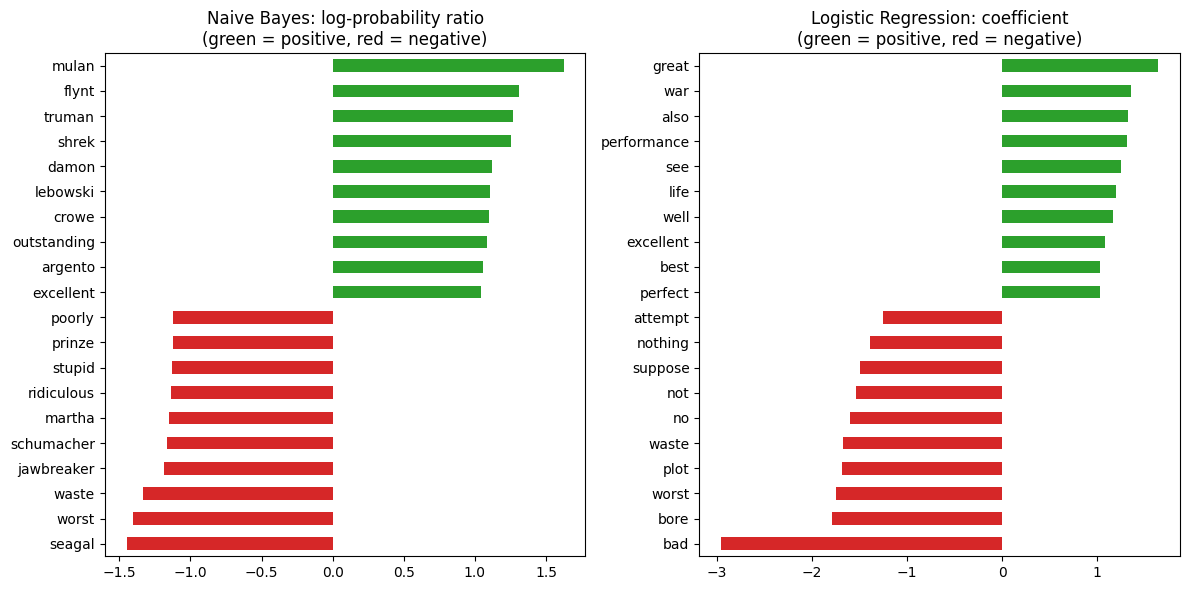

In [12]:
vocab = np.array(fitted["Multinomial Naive Bayes"].named_steps["tfidf"].get_feature_names_out())
nb_score = (fitted["Multinomial Naive Bayes"]["model"].feature_log_prob_[1]
            - fitted["Multinomial Naive Bayes"]["model"].feature_log_prob_[0])
lr_score = fitted["Logistic Regression"]["model"].coef_[0]

def extremes(score, k=10):
    order = np.argsort(score)
    idx = np.concatenate([order[:k], order[-k:]])
    return pd.Series(score[idx], index=vocab[idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (title, score) in zip(axes, [("Naive Bayes: log-probability ratio", nb_score),
                                      ("Logistic Regression: coefficient", lr_score)]):
    s = extremes(score)
    s.plot.barh(ax=ax, color=["tab:red" if v < 0 else "tab:green" for v in s])
    ax.set_title(title + "\n(green = positive, red = negative)")
fig.tight_layout()
fig.savefig(f"{OUT}/02_top_words.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"NB negative": extremes(nb_score).index[:10][::-1],
              "NB positive": extremes(nb_score).index[10:][::-1],
              "LR negative": extremes(lr_score).index[:10][::-1],
              "LR positive": extremes(lr_score).index[10:][::-1]}).to_csv(f"{OUT}/top_words.csv", index=False)

## Testing custom phrases

These models learned from movie reviews, so product-style phrases test how well they carry over to another domain. The negation cases are the hard ones: TF-IDF counts words and ignores their order, so "not good" is just "not" plus "good".

In [13]:
phrases = ["This movie was absolutely wonderful, I loved every minute",
           "Terrible plot and awful acting, a complete waste of time",
           "The film was not good",
           "It was not bad at all",
           "I didn't hate it",
           "Great value and durable build, would buy again",
           "The package arrived on Tuesday"]
rows = []
for p in phrases:
    row = {"Phrase": p}
    for name, pipe in fitted.items():
        label, conf = predict_sentiment(p, pipe, show=False)
        row[name] = f"{label} ({conf:.0%})" if label != "unknown" else "unknown"
    rows.append(row)
pd.DataFrame(rows)

,Phrase,Multinomial Naive Bayes,Logistic Regression
0,"This movie was absolutely wonderful, I loved e...",positive (52%),positive (55%)
1,"Terrible plot and awful acting, a complete was...",negative (86%),negative (87%)
2,The film was not good,negative (52%),positive (54%)
3,It was not bad at all,negative (74%),negative (96%)
4,I didn't hate it,negative (51%),negative (53%)
5,"Great value and durable build, would buy again",positive (53%),positive (66%)
6,The package arrived on Tuesday,positive (52%),positive (58%)


In [14]:
best_name = results.sort_values("Test accuracy", ascending=False)["Model"].iloc[0]
best_model = fitted[best_name]
print("Model used below:", best_name)

INTERACTIVE = False   # set to True to type your own phrases
if INTERACTIVE:
    while True:
        text = input("Type a review (press Enter to stop): ").strip()
        if not text:
            break
        predict_sentiment(text, best_model)

Model used below: Logistic Regression


## Results and interpretation

**Part A (10 provided reviews).** Nothing can be concluded. After dropping the neutral review, 9 reviews remain, and leave-one-out accuracy is 1 of 9 for both models because the reviews share almost no vocabulary. The pipeline works, but the file is too small to evaluate it.

**Part B (2,000 NLTK movie reviews, 1,600 train / 400 test).**

| Model | CV accuracy | Test accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Multinomial Naive Bayes | 0.826 ± 0.012 | 0.8025 | 0.827 | 0.765 | 0.795 | 0.891 |
| Logistic Regression | 0.844 ± 0.013 | 0.8350 | 0.813 | 0.870 | 0.841 | 0.915 |

- **Logistic Regression comes out ahead on every metric**, but the margin is modest. The test gap is 3.3 points on 400 reviews, and the cross-validated gap is 1.8 points against a spread of about 1.2 points, so I'd call it a likely edge and not a certain one. Naive Bayes is more precise (it calls fewer reviews positive); Logistic Regression catches more of the truly positive ones.
- **Adding bigrams barely helps**: cross-validated accuracy rises from 0.826 to 0.829 for Naive Bayes and from 0.844 to 0.847 for Logistic Regression, well inside the fold spread. The task specifies unigrams, and I kept them.
- **Naive Bayes latches onto names.** Its strongest "words" include `mulan`, `shrek`, `truman`, `seagal`, `schumacher` and `lebowski`. Those are properties of this particular corpus, and they will mean nothing for other reviews. Logistic Regression's top words (`great`, `excellent`, `bad`, `worst`, `waste`, `bore`) read far more sensibly, and `not` and `no` appear among its negative words, which supports keeping negations out of the stopword list.
- **Negation is the weak spot.** TF-IDF ignores word order. "The film was not good" gets a 52% negative call from Naive Bayes and a 54% positive call from Logistic Regression, both near a coin flip. "It was not bad at all" is labelled negative by both, which is wrong. These failures are expected from a bag-of-words model, not bugs.
- **Confidence is weak.** Naive Bayes probabilities sit close to 50% even on clear praise ("wonderful, I loved every minute" is 52%), so treat them as a ranking, not as calibrated probabilities.
- **The models have no neutral class.** "The package arrived on Tuesday" is forced to positive. A phrase with no known words returns "unknown" instead of a guess.

**Limitations.** The models learned movie language, so product-review phrases are a domain shift; one split (seed 42); no hyperparameter tuning; roughly 80% accuracy is typical for this setup on this corpus and is not a strong result by modern standards.
